## **에어제트 속도 및 온도 측정 실험**

기계시스템공학실험(B) 열유체 1주차

---
`data100_n_m`: x=100mm의 거리에서 바람 세기 n단, 열 세기 m단에서 측정한 위치별 데이터 

`data150_n_m`: x=150mm의 거리에서 바람 세기 n단, 열 세기 m단에서 측정한 위치별 데이터 

`df_info`: 8회의 실험에 대한 전체 유량, 전체 열전달율을 포함하는 실험 정보 데이터
<br><br>

실험 분석을 위해 사용한 라이브러리 및 용도는 다음과 같습니다.


`pandas`: csv 형태의 데이터를 처리하기 위해 사용하였다.

`matplotlib`: Python의 시각화 라이브러리로, 각종 그래프의 시각화를 위해 사용하였다.


<br><br>
이외 자세한 실험 과정 및 결과는 실험 보고서를 참고 바랍니다.

In [51]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib
plt.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus'] = False


file_path = r"D:\00 기계공학실험\열유체\Airjet_Temperature_Pressure.xlsx"
data100_1_0 = pd.read_excel(file_path, sheet_name='Sheet1', nrows=11)
data100_2_0 = pd.read_excel(file_path, sheet_name='Sheet2', nrows=11)
data100_1_1 = pd.read_excel(file_path, sheet_name='Sheet3', nrows=11)
data100_2_1 = pd.read_excel(file_path, sheet_name='Sheet4', nrows=10)

data150_1_0 = pd.read_excel(file_path, sheet_name='Sheet5', nrows=12)
data150_2_0 = pd.read_excel(file_path, sheet_name='Sheet6', nrows=12)
data150_1_1 = pd.read_excel(file_path, sheet_name='Sheet7', nrows=12)
data150_2_1 = pd.read_excel(file_path, sheet_name='Sheet8', nrows=12)

data100_1_0

,i,position,temperature,p_diff,t_diff,rho,velocity,Ai,Qi,Pi,Qi_l/min
0,1,0,23.21,286.0,2.21,1.191076,21.914334,28.2735,619.594923,1.639101e+06,37.175695
1,2,3,23.45,294.0,2.45,1.190112,22.227709,84.8205,1885.365406,5.524788e+06,113.121924
2,3,6,23.53,297.0,2.53,1.189791,22.343841,141.3675,3158.692905,9.555750e+06,189.521574
3,4,9,23.41,298.0,2.41,1.190273,22.376898,197.9145,4428.712615,1.276754e+07,265.722757
4,5,12,23.08,230.0,2.08,1.191599,19.647799,254.4615,4999.608381,1.245361e+07,299.976503
5,6,15,22.50,145.0,1.50,1.193936,15.585058,311.0085,4847.085368,8.724071e+06,290.825122
6,7,18,22.49,73.0,1.49,1.193977,11.058049,367.5555,4064.446580,7.266907e+06,243.866795
7,8,21,21.89,27.0,0.89,1.196405,6.718275,424.1025,2849.237368,3.049038e+06,170.954242
8,9,24,21.85,4.0,0.85,1.196567,2.585690,480.6495,1242.810649,1.270361e+06,74.568639
9,10,27,21.44,0.1,0.44,1.198232,0.408549,537.1965,219.471252,1.162887e+05,13.168275


In [52]:
df_info = pd.read_excel("D:/00 기계공학실험/열유체/Experiment_Info.xlsx")
df_info

,x_axis,wind,heat,t_room,p_therm,p_elec,efficiency,Q
0,100,1,0,21,62.37,76.8,0.812109,1698.9
1,100,2,0,21,95.51,100.7,0.948461,1878.8
2,100,1,1,22,744.90,919.5,0.810114,1763.4
3,100,2,1,22,870.90,920.0,0.946630,2047.9
4,150,1,0,22,76.76,76.2,1.007349,1895.3
5,150,2,0,22,75.84,101.5,0.747192,2161.6
6,150,1,1,22,691.40,929.0,0.744241,1991.2
7,150,2,1,22,784.60,1052.0,0.745817,2300.5


### **유량 비교**

- 전체 실험에서의 미소유량 비교

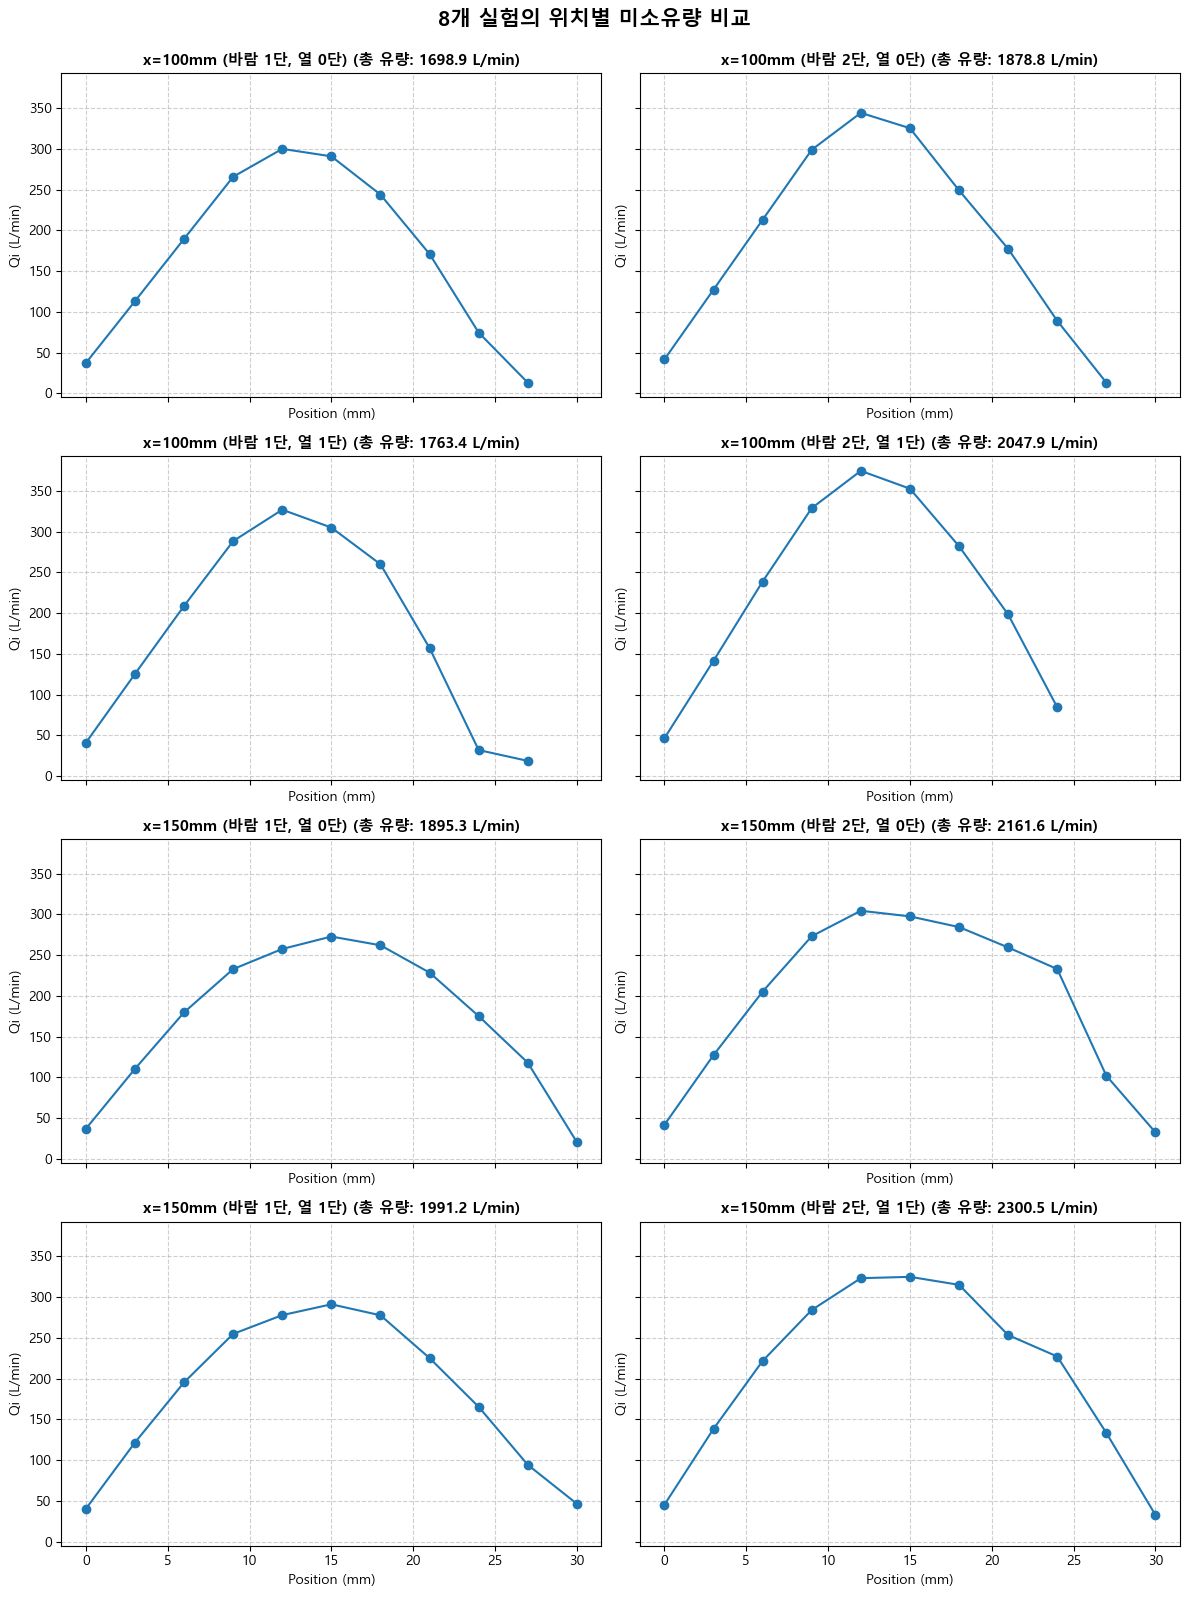

In [ ]:
datasets = [
    (data100_1_0, "x=100mm (바람 1단, 열 0단)"),
    (data100_2_0, "x=100mm (바람 2단, 열 0단)"),
    (data100_1_1, "x=100mm (바람 1단, 열 1단)"),
    (data100_2_1, "x=100mm (바람 2단, 열 1단)"),
    (data150_1_0, "x=150mm (바람 1단, 열 0단)"),
    (data150_2_0, "x=150mm (바람 2단, 열 0단)"),
    (data150_1_1, "x=150mm (바람 1단, 열 1단)"),
    (data150_2_1, "x=150mm (바람 2단, 열 1단)")]

## 그래프 
fig, axes = plt.subplots(4, 2, figsize=(12, 16), sharex=True, sharey=True)
axes = axes.flatten()  

for i, (df, title) in enumerate(datasets):
    ax = axes[i]
    ax.plot(df['position'], df['Qi_l/min'], marker='o', linestyle='-', color='tab:blue')
    
    total_q = df_info.loc[i, 'Q']
    ax.set_title(f"{title} (총 유량: {total_q:.1f} L/min)", fontsize=11, fontweight='bold')
    ax.set_xlabel("Position (mm)")
    ax.set_ylabel("Qi (L/min)")
    ax.grid(True, linestyle='--', alpha=0.6)

plt.suptitle("8개 실험의 위치별 미소유량 비교", fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

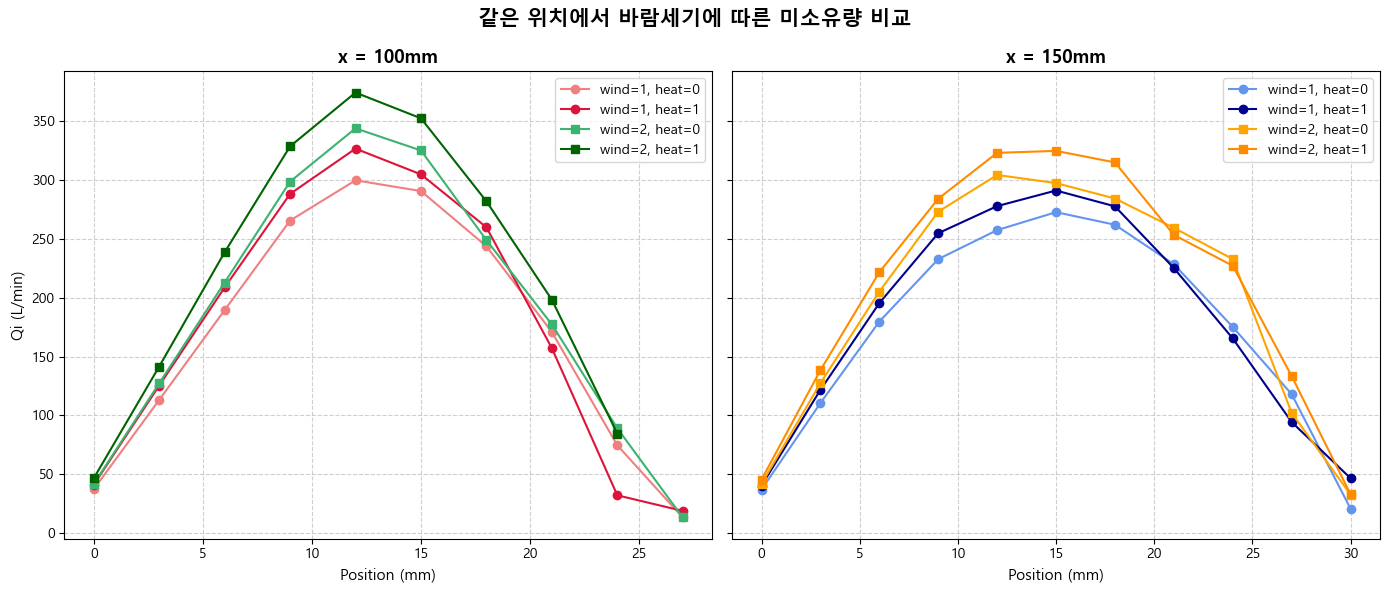

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# x=100mm의 경우
axes[0].plot(data100_1_0['position'], data100_1_0['Qi_l/min'], marker='o', linestyle='-', color='lightcoral',     label='wind=1, heat=0')
axes[0].plot(data100_1_1['position'], data100_1_1['Qi_l/min'], marker='o', linestyle='-',  color='crimson',        label='wind=1, heat=1')
axes[0].plot(data100_2_0['position'], data100_2_0['Qi_l/min'], marker='s', linestyle='-', color='mediumseagreen', label='wind=2, heat=0')
axes[0].plot(data100_2_1['position'], data100_2_1['Qi_l/min'], marker='s', linestyle='-',  color='darkgreen',      label='wind=2, heat=1')

axes[0].set_title("x = 100mm", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Position (mm)", fontsize=11)
axes[0].set_ylabel("Qi (L/min)", fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# x=150mm의 경우
axes[1].plot(data150_1_0['position'], data150_1_0['Qi_l/min'], marker='o', linestyle='-', color='cornflowerblue', label='wind=1, heat=0')
axes[1].plot(data150_1_1['position'], data150_1_1['Qi_l/min'], marker='o', linestyle='-',  color='darkblue',       label='wind=1, heat=1')
axes[1].plot(data150_2_0['position'], data150_2_0['Qi_l/min'], marker='s', linestyle='-', color='orange',         label='wind=2, heat=0')
axes[1].plot(data150_2_1['position'], data150_2_1['Qi_l/min'], marker='s', linestyle='-',  color='darkorange',     label='wind=2, heat=1')

axes[1].set_title("x = 150mm", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Position (mm)", fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle("같은 위치에서 바람세기에 따른 미소유량 비교", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

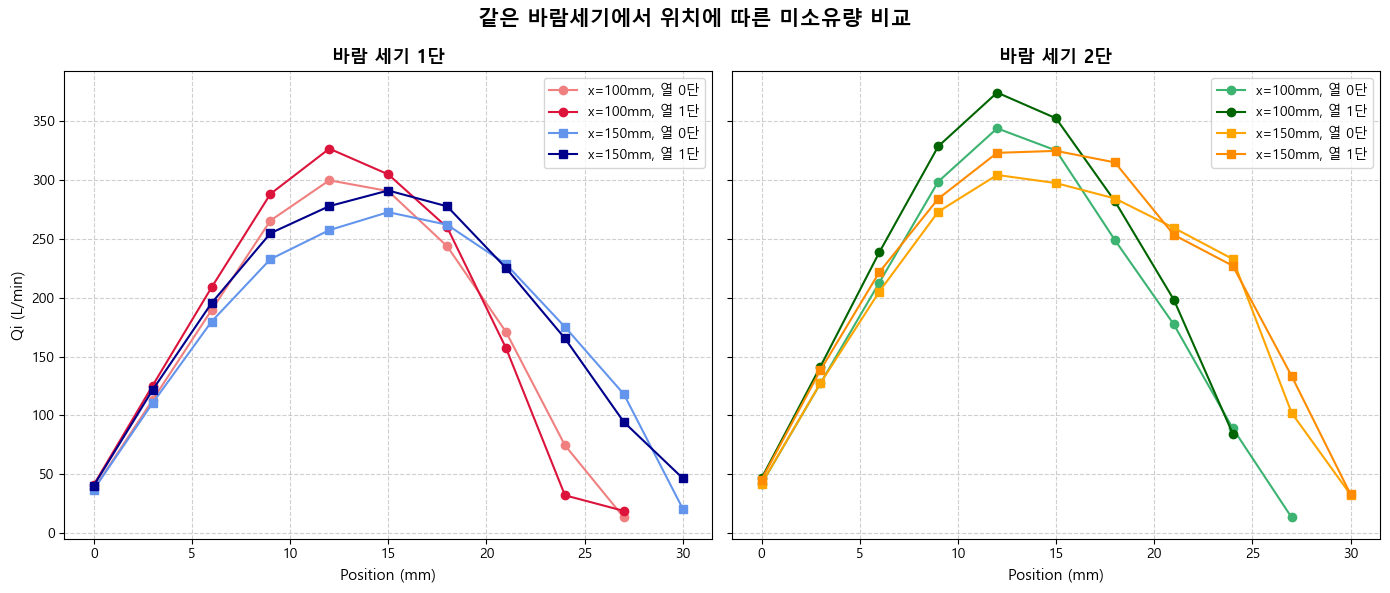

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# 바람 세기 1단
axes[0].plot(data100_1_0['position'], data100_1_0['Qi_l/min'], marker='o', linestyle='-', color='lightcoral',     label='x=100mm, 열 0단')
axes[0].plot(data100_1_1['position'], data100_1_1['Qi_l/min'], marker='o', linestyle='-',  color='crimson',        label='x=100mm, 열 1단')
axes[0].plot(data150_1_0['position'], data150_1_0['Qi_l/min'], marker='s', linestyle='-', color='cornflowerblue', label='x=150mm, 열 0단')
axes[0].plot(data150_1_1['position'], data150_1_1['Qi_l/min'], marker='s', linestyle='-',  color='darkblue',       label='x=150mm, 열 1단')

axes[0].set_title("바람 세기 1단", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Position (mm)", fontsize=11)
axes[0].set_ylabel("Qi (L/min)", fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# 바람 세기 2단
axes[1].plot(data100_2_0['position'], data100_2_0['Qi_l/min'], marker='o', linestyle='-', color='mediumseagreen', label='x=100mm, 열 0단')
axes[1].plot(data100_2_1['position'], data100_2_1['Qi_l/min'], marker='o', linestyle='-',  color='darkgreen',      label='x=100mm, 열 1단')
axes[1].plot(data150_2_0['position'], data150_2_0['Qi_l/min'], marker='s', linestyle='-', color='orange',         label='x=150mm, 열 0단')
axes[1].plot(data150_2_1['position'], data150_2_1['Qi_l/min'], marker='s', linestyle='-',  color='darkorange',     label='x=150mm, 열 1단')

axes[1].set_title("바람 세기 2단", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Position (mm)", fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle("같은 바람세기에서 위치에 따른 미소유량 비교", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### **미소 열전달율**

- 같은 위치에서 열 세기에 따른 비교

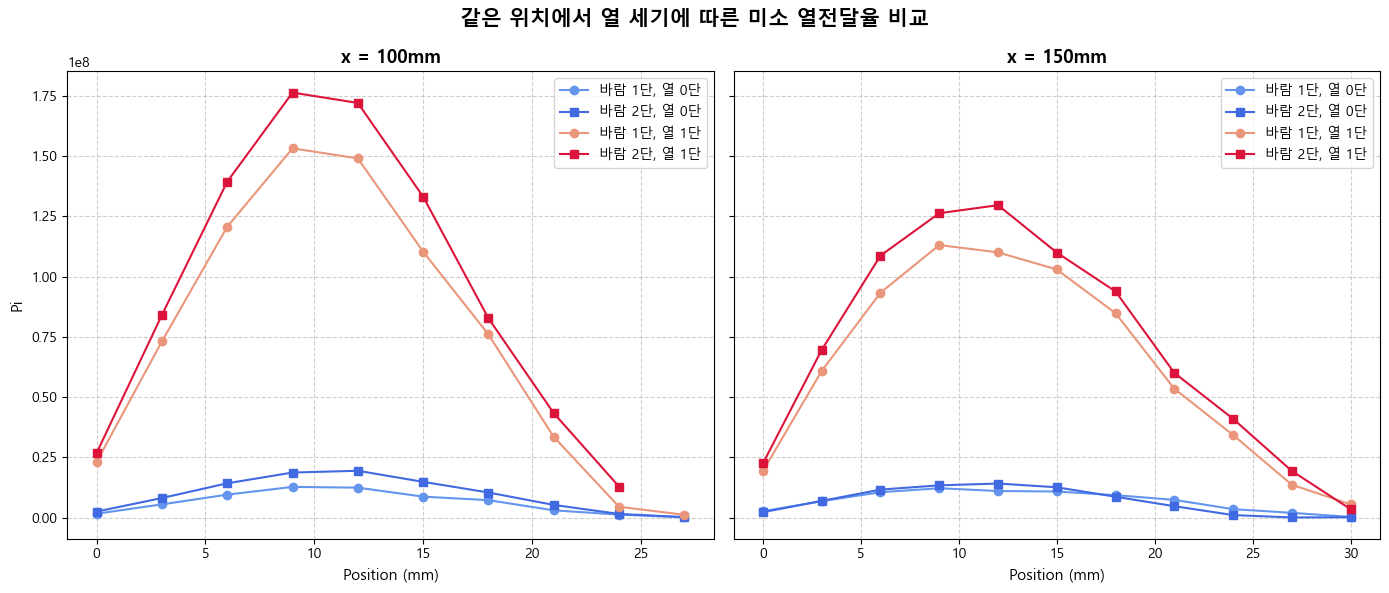

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# x=100mm
axes[0].plot(data100_1_0['position'], data100_1_0['Pi'], marker='o', linestyle='-', color='cornflowerblue', label='바람 1단, 열 0단')
axes[0].plot(data100_2_0['position'], data100_2_0['Pi'], marker='s', linestyle='-', color='royalblue',      label='바람 2단, 열 0단')
axes[0].plot(data100_1_1['position'], data100_1_1['Pi'], marker='o', linestyle='-',  color='darksalmon',     label='바람 1단, 열 1단')
axes[0].plot(data100_2_1['position'], data100_2_1['Pi'], marker='s', linestyle='-',  color='crimson',        label='바람 2단, 열 1단')

axes[0].set_title("x = 100mm", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Position (mm)", fontsize=11)
axes[0].set_ylabel("Pi", fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# x=150mm
axes[1].plot(data150_1_0['position'], data150_1_0['Pi'], marker='o', linestyle='-', color='cornflowerblue', label='바람 1단, 열 0단')
axes[1].plot(data150_2_0['position'], data150_2_0['Pi'], marker='s', linestyle='-', color='royalblue',      label='바람 2단, 열 0단')
axes[1].plot(data150_1_1['position'], data150_1_1['Pi'], marker='o', linestyle='-',  color='darksalmon',     label='바람 1단, 열 1단')
axes[1].plot(data150_2_1['position'], data150_2_1['Pi'], marker='s', linestyle='-',  color='crimson',        label='바람 2단, 열 1단')

axes[1].set_title("x = 150mm", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Position (mm)", fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle("같은 위치에서 열 세기에 따른 미소 열전달율 비교", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### **속도**

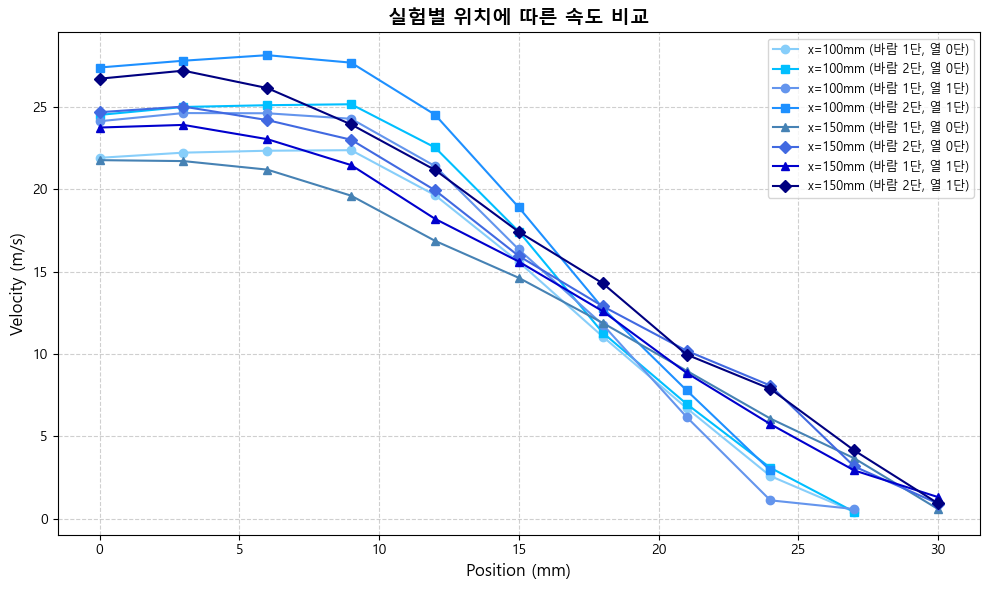

In [ ]:
datasets = [
    (data100_1_0, "x=100mm (바람 1단, 열 0단)", "lightskyblue",   "o", "-"),
    (data100_2_0, "x=100mm (바람 2단, 열 0단)", "deepskyblue",    "s", "-"),
    (data100_1_1, "x=100mm (바람 1단, 열 1단)", "cornflowerblue", "o", "-"),
    (data100_2_1, "x=100mm (바람 2단, 열 1단)", "dodgerblue",     "s", "-"),
    (data150_1_0, "x=150mm (바람 1단, 열 0단)", "steelblue",      "^", "-"),
    (data150_2_0, "x=150mm (바람 2단, 열 0단)", "royalblue",      "D", "-"),
    (data150_1_1, "x=150mm (바람 1단, 열 1단)", "mediumblue",     "^", "-"),
    (data150_2_1, "x=150mm (바람 2단, 열 1단)", "navy",           "D", "-")]

plt.figure(figsize=(10, 6))

for df, label, color, marker, ls in datasets:
    plt.plot(df['position'], df['velocity'], color=color, marker=marker, linestyle=ls, label=label)

plt.title("실험별 위치에 따른 속도 비교", fontsize=14, fontweight='bold')
plt.xlabel("Position (mm)", fontsize=12)
plt.ylabel("Velocity (m/s)", fontsize=12)
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

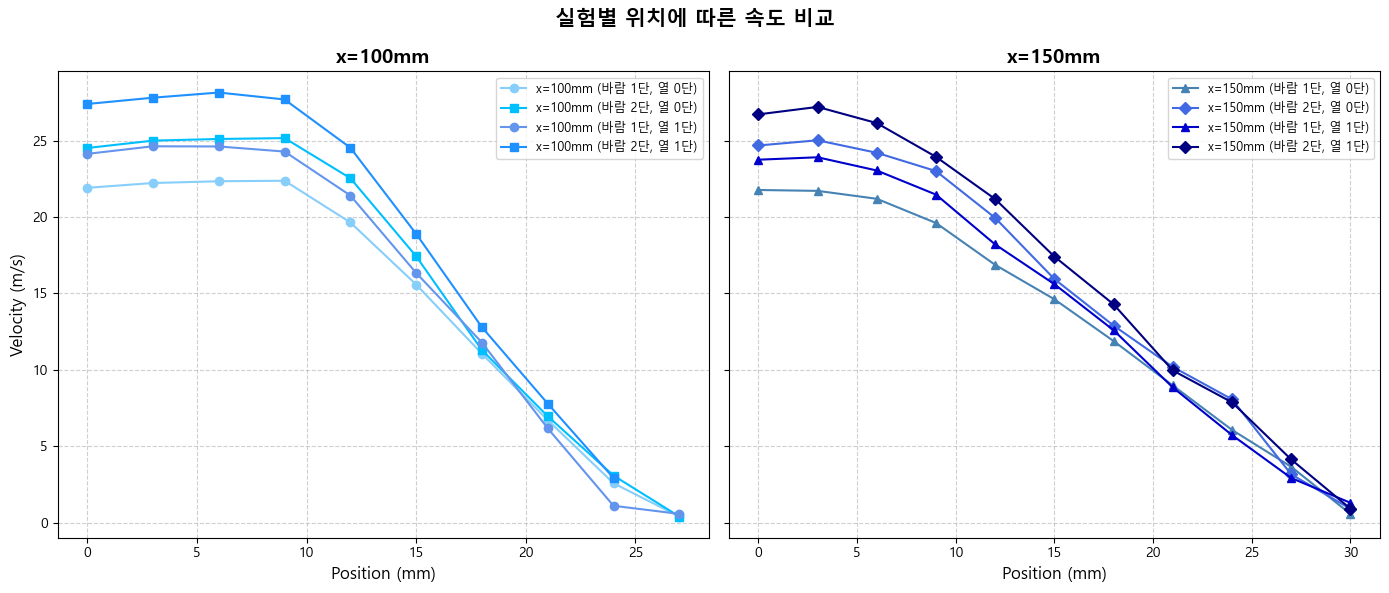

In [ ]:
datasets_100 = [
    (data100_1_0, "x=100mm (바람 1단, 열 0단)", "lightskyblue",   "o", "-"),
    (data100_2_0, "x=100mm (바람 2단, 열 0단)", "deepskyblue",    "s", "-"),
    (data100_1_1, "x=100mm (바람 1단, 열 1단)", "cornflowerblue", "o", "-"),
    (data100_2_1, "x=100mm (바람 2단, 열 1단)", "dodgerblue",     "s", "-"),
]

datasets_150 = [
    (data150_1_0, "x=150mm (바람 1단, 열 0단)", "steelblue",      "^", "-"),
    (data150_2_0, "x=150mm (바람 2단, 열 0단)", "royalblue",      "D", "-"),
    (data150_1_1, "x=150mm (바람 1단, 열 1단)", "mediumblue",     "^", "-"),
    (data150_2_1, "x=150mm (바람 2단, 열 1단)", "navy",           "D", "-"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# x=100mm
for df, label, color, marker, ls in datasets_100:
    axes[0].plot(df['position'], df['velocity'], color=color, marker=marker, linestyle=ls, label=label)

axes[0].set_title("x=100mm", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Position (mm)", fontsize=12)
axes[0].set_ylabel("Velocity (m/s)", fontsize=12)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.6)

# x=150mm
for df, label, color, marker, ls in datasets_150:
    axes[1].plot(df['position'], df['velocity'], color=color, marker=marker, linestyle=ls, label=label)

axes[1].set_title("x=150mm", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Position (mm)", fontsize=12)
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle("실험별 위치에 따른 속도 비교", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()